# Hora da verdade!
Agora com todas as análises que fizemos, e dados que que estruturamos, temos insumos o suficiente para fazer uma recomendação para um cliente com base nos investimentos que ele possui na carteira


## 1. Importar as Libs🔥

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

## 2. Recebimentos dos dados🤖
Aqui mockamos um novo cliente, mas quando a API estiver disponível receberemos isso via POST

In [2]:
#dados do usuário
id_novo_cliente = '69' #    ID do novo cliente
ativos_novo_cliente = [('1832421D CN', 1436.22), ('1SANPN', 1436.22), ('2458693D US',1436.22), ('IGSN14 CDIE', 10000)] #    Ativos do novo cliente
classificacao_do_forms = 'Conservador' #    Classificação do Forms

## 3. Carregar os dados😏

Aqui a gente só carrega as planilhas que fizemos e serão necessárias para o processo. Além disso, para as planilhas que não tinhamos definido a conta como índicie, fazemos esse ajuste

In [3]:
df_subgrupo_dist = pd.read_csv('../data/processed/subgrupo_distribuicao.csv')
df_user_item = pd.read_csv('../data/processed/user_item_binario.csv')
df_class_tipos = pd.read_csv('../data/raw/classificacao_de_tipos.csv') # Para detalhes dos ativos no final
barema_por_ativo = pd.read_csv('../data/processed/barema_por_ativo.csv')


if 'CONTA' in df_subgrupo_dist.columns:
    df_subgrupo_dist.set_index('CONTA', inplace=True)
else:
    print("Erro: Coluna 'CONTA' não encontrada em subgrupo_distribuicao.csv")
    raise KeyError("Coluna 'CONTA' ausente")

if 'CONTA' in df_user_item.columns:
    df_user_item.set_index('CONTA', inplace=True)
elif 'Conta' in df_user_item.columns:
    df_user_item.rename(columns={'Conta':'CONTA'}, inplace=True)
    df_user_item.set_index('CONTA', inplace=True)
else:
    print("Erro: Coluna 'CONTA' (ou 'Conta') não encontrada em user_item_binario.csv")
    raise KeyError("Coluna 'CONTA' (ou 'Conta') ausente")
    
print("Dados carregados e preparados.")

Dados carregados e preparados.


## 4. Classificação do cliente e "Recomendação!?"😱

Isso mesmo que você leu, nessa etapa além de fazer a classificação do cliente, também já podemos fazer algumas recomendações, mas ainda não recomendações relacionadas ao ativo, mas sim do quanto investir.

### Classificação do usuário em Conservador, Moderado ou Sofisticado

primeiro vamos ver quanto ele investe em Renda Fixa e Renda Variável

Distribuição Financeira de Investimentos do Usuário:
Valores:
CLASSIFICACAO DO ATIVO
Renda Fixa        10000.00
Renda Variável     4308.66
Name: VALOR INVESTIDO, dtype: float64

Percentual:
CLASSIFICACAO DO ATIVO
Renda Fixa        69.89
Renda Variável    30.11
Name: VALOR INVESTIDO, dtype: float64%


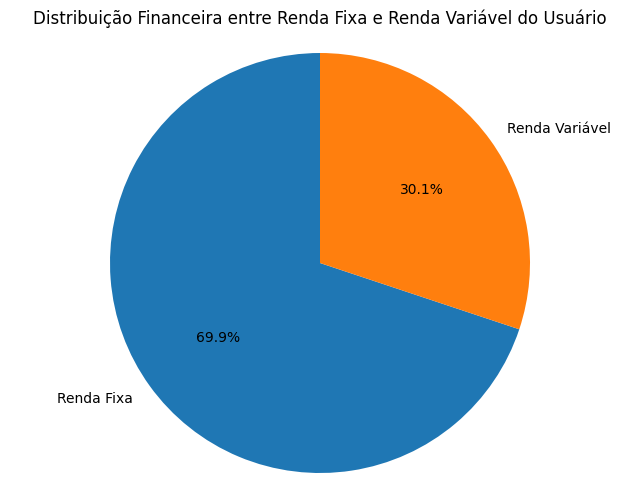

In [4]:
ativos_dict = {item[0]: item[1] for item in ativos_novo_cliente}

filtered_barema = barema_por_ativo[barema_por_ativo['NOME ATIVO'].isin(ativos_dict.keys())].copy()

if filtered_barema.empty:
    print("Nenhum dos ativos do usuário foi encontrado no barema.")
else:
    filtered_barema['VALOR INVESTIDO'] = filtered_barema['NOME ATIVO'].map(ativos_dict)

    distribuicao_financeira = filtered_barema.groupby('CLASSIFICACAO DO ATIVO')['VALOR INVESTIDO'].sum()

    total_investido = distribuicao_financeira.sum()

    percentual_financeiro = (distribuicao_financeira / total_investido * 100).round(2)

    print("Distribuição Financeira de Investimentos do Usuário:")
    print(f"Valores:\n{distribuicao_financeira}")
    print(f"\nPercentual:\n{percentual_financeiro}%")

    plt.figure(figsize=(8, 6))
    plt.pie(distribuicao_financeira, labels=distribuicao_financeira.index, autopct='%1.1f%%', startangle=90)
    plt.axis('equal')
    plt.title('Distribuição Financeira entre Renda Fixa e Renda Variável do Usuário')
    plt.show()

Uma vez que sabemos sua distribuição de renda entre Renda Fixa e Renda Variável, podemos concluir seu perfil

In [5]:
renda_fixa_pct = percentual_financeiro['Renda Fixa']
renda_variavel_pct = percentual_financeiro['Renda Variável']

if renda_fixa_pct >= 90.0:
    classificacao = "Conservador"
elif renda_variavel_pct >= 70.0:
    classificacao = "Sofisticado/Arrojado"
else:
    classificacao = "Moderado"

print(f"Perfil do investidor: {classificacao}")


Perfil do investidor: Moderado


### Encontrar valor de adequação de carteira

Mas se a gente sabe o quanto ele investe, sabe quantos por cento o valor investido precisa representar do total para ele voltar para o seu antigo perfil, logo:

In [6]:
print(f"Classificação do Forms: {classificacao_do_forms}")
print(f"Classificação Calculada: {classificacao}")

renda_fixa_atual = distribuicao_financeira['Renda Fixa']
renda_variavel_atual = distribuicao_financeira['Renda Variável']

total = renda_fixa_atual + renda_variavel_atual

renda_fixa_pct = (renda_fixa_atual / total) * 100
renda_variavel_pct = (renda_variavel_atual / total) * 100

if classificacao != classificacao_do_forms:
    print("\nAs classificações são diferentes. Calculando ajustes necessários...")

    if classificacao_do_forms == "Conservador":
        percentual_desejado = 90.0
        if renda_fixa_pct < percentual_desejado:
            valor_adicional = ((percentual_desejado * total) - (100 * renda_fixa_atual)) / (100 - percentual_desejado)
            print(f"Para alcançar o perfil Conservador, você precisa adicionar R$ {valor_adicional.round(2)} em Renda Fixa.")
            type_to_buy = "Renda Fixa"

    elif classificacao_do_forms == "Sofisticado/Arrojado":
        percentual_desejado = 70.0
        if renda_variavel_pct < percentual_desejado:
            valor_adicional = ((percentual_desejado * total) - (100 * renda_variavel_atual)) / (100 - percentual_desejado)
            print(f"Para alcançar o perfil Sofisticado/Arrojado, você precisa adicionar R$ {valor_adicional.round(2)} em Renda Variável.")
            type_to_buy = "Renda Variável"

    elif classificacao_do_forms == "Moderado":
        if renda_fixa_pct >= 90.0:
            percentual_desejado = 40.0
            valor_adicional = ((percentual_desejado * total) - (100 * renda_variavel_atual)) / (100 - percentual_desejado)
            print(f"Para alcançar o perfil Moderado, você precisa adicionar R$ {valor_adicional.round(2)} em Renda Variável.")
            type_to_buy = "Renda Variável"
        elif renda_variavel_pct >= 70.0:
            percentual_desejado = 40.0
            valor_adicional = ((percentual_desejado * total) - (100 * renda_fixa_atual)) / (100 - percentual_desejado)
            print(f"Para alcançar o perfil Moderado, você precisa adicionar R$ {valor_adicional.round(2)} em Renda Fixa.")
            type_to_buy = "Renda Fixa"
        else:
            print("Você já está dentro dos parâmetros para o perfil Moderado, mas sua alocação atual é:")
            print(f"Renda Fixa: {renda_fixa_pct.round(2)}%")
            print(f"Renda Variável: {renda_variavel_pct.round(2)}%")
else:
    print("\nA classificação calculada já está de acordo com a classificação do formulário.")


Classificação do Forms: Conservador
Classificação Calculada: Moderado

As classificações são diferentes. Calculando ajustes necessários...
Para alcançar o perfil Conservador, você precisa adicionar R$ 28777.94 em Renda Fixa.


Agora já sabendo o quanto a gente precisa recomendar pra esse usuário, resta saber quais ativos recomendar!

## 5. Filtragem Colaborativa por usuário🐐

In [7]:
print(ativos_novo_cliente)
df_carteira_novo_cliente = pd.DataFrame(ativos_novo_cliente, columns=['Ativo', 'VALOR INVESTIDO'])

df_carteira_novo_cliente = pd.merge(
    df_carteira_novo_cliente,
    filtered_barema[['NOME ATIVO', 'CLASSIFICACAO DO ATIVO']],
    left_on='Ativo',
    right_on='NOME ATIVO',
    how='left'
)
classificacao_to_subgrupo = {}
for idx, row in df_class_tipos.iterrows():
    classificacao = row['Classificacao']
    subgrupo = row['Subgrupo']
    if classificacao not in classificacao_to_subgrupo:
        classificacao_to_subgrupo[classificacao] = []
    if subgrupo not in classificacao_to_subgrupo[classificacao]:
        classificacao_to_subgrupo[classificacao].append(subgrupo)

def map_to_subgrupo(row):
    if pd.isnull(row['CLASSIFICACAO DO ATIVO']):
        return None
    
    ativo = row['Ativo']
    if 'CDIE' in ativo:
        return 'RF - Títulos Privados Nacionais' if row['CLASSIFICACAO DO ATIVO'] == 'Renda Fixa' else None
    elif any(term in ativo for term in ['CN', 'US', 'HK', 'JP']):
        return 'RV - Ações Internacionais e ADRs' if row['CLASSIFICACAO DO ATIVO'] == 'Renda Variável' else None
    elif ativo.isalpha() and len(ativo) <= 5 and 'PN' in ativo:
        return 'RV - Ações Nacionais' if row['CLASSIFICACAO DO ATIVO'] == 'Renda Variável' else None
    
    classification = row['CLASSIFICACAO DO ATIVO']
    if classification in classificacao_to_subgrupo and classificacao_to_subgrupo[classification]:
        return classificacao_to_subgrupo[classification][0]
    return None

df_carteira_novo_cliente['Subgrupo'] = df_carteira_novo_cliente.apply(map_to_subgrupo, axis=1)
df_carteira_novo_cliente = df_carteira_novo_cliente[['Ativo', 'VALOR INVESTIDO', 'Subgrupo']]

df_carteira_novo_cliente


[('1832421D CN', 1436.22), ('1SANPN', 1436.22), ('2458693D US', 1436.22), ('IGSN14 CDIE', 10000)]


,Ativo,VALOR INVESTIDO,Subgrupo
0,1832421D CN,1436.22,RV - Ações Internacionais e ADRs
1,1SANPN,1436.22,RV - Ações Internacionais e ADRs
2,2458693D US,1436.22,RV - Ações Internacionais e ADRs
3,IGSN14 CDIE,10000.00,RF - Títulos Privados Nacionais


Sabendo o quanto esse usuário investe em cada subgrupo, plotamos um gráfico para ter um indicador visual da distribuição de renda desse usuário, e ainda calculamos o percentual de destribuição de renda dele entre os subgrupos

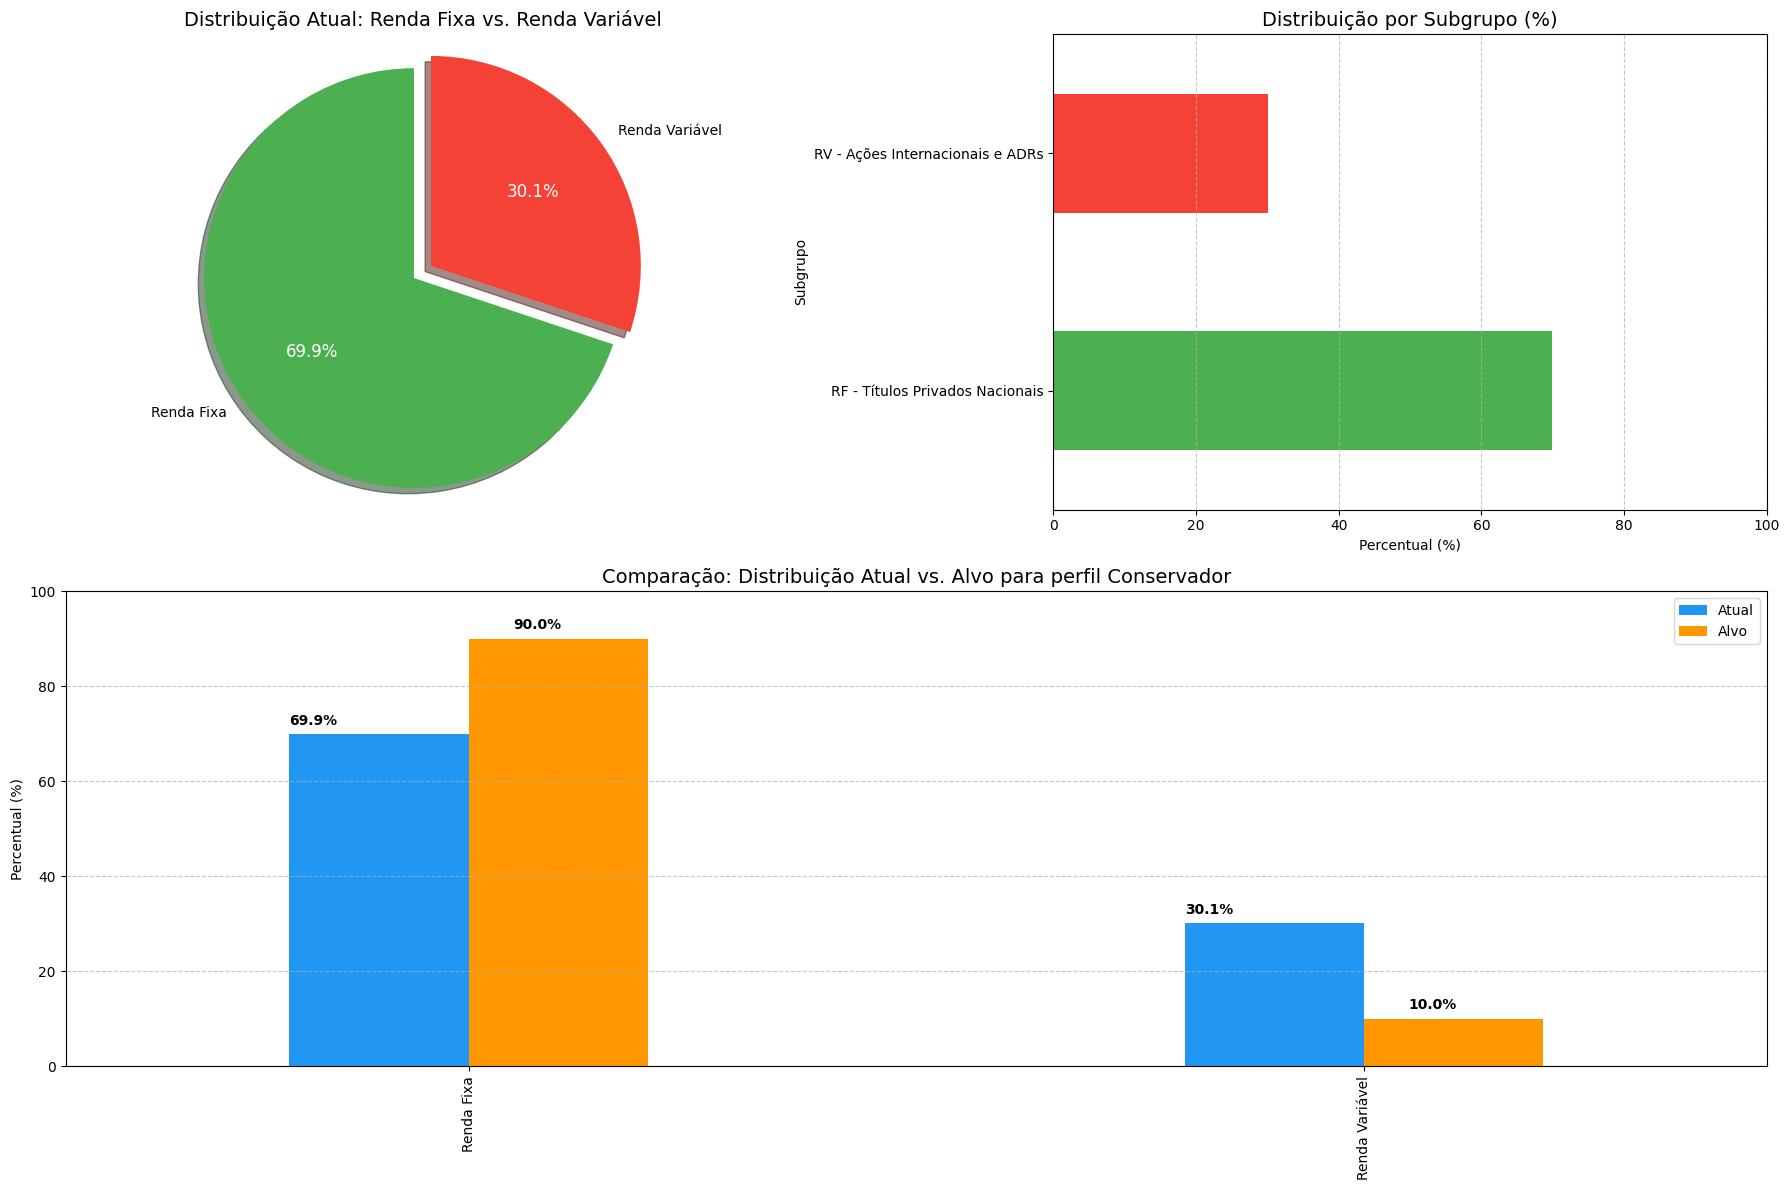


Distribuição Detalhada por Subgrupo:


,Subgrupo,Valor Investido (R$),Percentual (%)
0,RF - Títulos Privados Nacionais,10000.00,69.89
1,RV - Ações Internacionais e ADRs,4308.66,30.11


In [8]:
fig = plt.figure(figsize=(18, 12))
grid = plt.GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(grid[0, 0])
wedges, texts, autotexts = ax1.pie(
    distribuicao_financeira, 
    labels=distribuicao_financeira.index, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['#4CAF50', '#F44336'], 
    explode=[0.05, 0.05], 
    shadow=True
)
ax1.set_title('Distribuição Atual: Renda Fixa vs. Renda Variável', fontsize=14)
ax1.axis('equal')
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)

ax2 = fig.add_subplot(grid[0, 1])
subgrupo_dist = df_carteira_novo_cliente.groupby('Subgrupo')['VALOR INVESTIDO'].sum().sort_values(ascending=False)
subgrupo_pct = (subgrupo_dist / subgrupo_dist.sum() * 100).round(2)

colors = ['#4CAF50' if 'RF' in idx else '#F44336' for idx in subgrupo_dist.index]

subgrupo_pct.plot(kind='barh', ax=ax2, color=colors)
ax2.set_title('Distribuição por Subgrupo (%)', fontsize=14)
ax2.set_xlabel('Percentual (%)')
ax2.set_xlim(0, 100)
ax2.grid(axis='x', linestyle='--', alpha=0.7)

ax3 = fig.add_subplot(grid[1, :])

atual_rf = percentual_financeiro['Renda Fixa']
atual_rv = percentual_financeiro['Renda Variável']

if classificacao_do_forms == 'Conservador':
    alvo_rf = 90
    alvo_rv = 10
elif classificacao_do_forms == 'Sofisticado/Arrojado':
    alvo_rf = 30
    alvo_rv = 70
else:  
    alvo_rf = 60
    alvo_rv = 40

comparison_data = pd.DataFrame({
    'Atual': [atual_rf, atual_rv],
    'Alvo': [alvo_rf, alvo_rv]
}, index=['Renda Fixa', 'Renda Variável'])

comparison_data.plot(kind='bar', ax=ax3, color=['#2196F3', '#FF9800'], width=0.4)
ax3.set_title(f'Comparação: Distribuição Atual vs. Alvo para perfil {classificacao_do_forms}', fontsize=14)
ax3.set_ylabel('Percentual (%)')
ax3.set_ylim(0, 100)
ax3.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(comparison_data['Atual']):
    ax3.text(i-0.2, v+2, f"{v:.1f}%", color='black', fontweight='bold')
    
for i, v in enumerate(comparison_data['Alvo']):
    ax3.text(i+0.05, v+2, f"{v:.1f}%", color='black', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nDistribuição Detalhada por Subgrupo:")
subgroup_df = pd.DataFrame({
    'Subgrupo': subgrupo_dist.index,
    'Valor Investido (R$)': subgrupo_dist.values.round(2),
    'Percentual (%)': subgrupo_pct.values.round(2)
})
display(subgroup_df)

In [9]:
novo_cliente_dist = pd.Series(0.0, index=df_subgrupo_dist.columns)

for subgrupo, pct in subgrupo_pct.items():
    if subgrupo in novo_cliente_dist.index:
        novo_cliente_dist[subgrupo] = pct

similarities = cosine_similarity(
    novo_cliente_dist.values.reshape(1, -1), 
    df_subgrupo_dist.values
)

similarities = similarities[0]

similar_mask = similarities >= 0.7 # ! TODO: Estudar um pouco mais sobre o threshold
similar_accounts = df_subgrupo_dist.index[similar_mask].tolist()
similar_scores = similarities[similar_mask]

result_df = pd.DataFrame({
    'CONTA': similar_accounts,
    'Similaridade': similar_scores
})

result_df = result_df.sort_values('Similaridade', ascending=False)

print(f"Encontradas {len(similar_accounts)} contas com similaridade >= 0.7")
result_df.tail(10) 

Encontradas 2504 contas com similaridade >= 0.7


,CONTA,Similaridade
762,299811,0.719329
1299,845866,0.712172
1627,1338802,0.711108
496,160456,0.710317
39,9958,0.709256
2049,4523552,0.706562
1464,1082901,0.703435
1115,659311,0.702865
840,339252,0.701267
1834,2533440,0.700713


Aqui pegamos todas as carteiras com 70% de similaridade de cosseno com a carteira do usuário. Esse valor foi arbitrário e pode ser contexto/estudado.

Encontradas as carteiras que costumam investir nos mesmos subgrupos de ativos, agora conseguimos encontrar um nicho de pessoas que livra a gente de procupações como:
- Viés de popularidade (mesmo que tenha uma popularidade grotesca nesse conjunto, só é popular entre pessoas de perfil parecido)
- Investimentos de renda variavel que se divergem muito serem considerados para recomendação

## 6. Filtragem colaborativa por Item😎

### Definir objetivo do usuário
Nesse ponto, sabemos o perfil que o usuário deve voltar, mas também sabemos os ativos que o usuário já comprou e tem dinheiro ativo. O que o usuário busca exatamente? Ele quer voltar para o perfil original ou prefere ficar nessa onda de investidor exótico por mais algum tempo?

In [12]:
voltar_ao_grupo = True

Para isso, criamos a variavel booleana que vai ser passada por requsiição para caso o usuário queira voltar pro grupo, ele só receba ativos que vão colaborar para ele voltar ao grupo original

### Conseguir recomendações
Uma vez que temos uma lista de pessoas que tem perfis de investimento parecido, temos uma lista de ativos que essas pessoas tem, e além disso, já sabemos quantos reais essa pessoa precisa investir, basta saber em quais ativos investir, e a abordagem escolhida para isso foi a filtragem colaborativa por item, no intuito de encontrar tendências entre pessoas de mesmo perfil e que possuem os mesmos ativos que o usuário

In [13]:
item_similarity = cosine_similarity(df_user_item.T.values)
item_sim_df = pd.DataFrame(
    item_similarity, 
    index=df_user_item.columns, 
    columns=df_user_item.columns
)

item_scores = pd.Series(0.0, index=df_user_item.columns)

for asset in ativos_dict.keys():
    if asset in item_sim_df.index:
        similar_assets = item_sim_df[asset].drop(ativos_dict.keys(), errors='ignore')
        item_scores += similar_assets

if voltar_ao_grupo:
    print(f"Filtrando recomendações para incluir apenas ativos do tipo: {type_to_buy}")
    ativos_by_type = barema_por_ativo[barema_por_ativo['CLASSIFICACAO DO ATIVO'] == type_to_buy]['NOME ATIVO'].tolist()
    item_scores = item_scores[item_scores.index.isin(ativos_by_type)]

recommendations = item_scores.sort_values(ascending=False).head(10)

recommendations_df = pd.DataFrame({
    'Ativo': recommendations.index,
    'Score': recommendations.values.round(3)
})

asset_info = []
for asset in recommendations_df['Ativo']:
    info = barema_por_ativo[barema_por_ativo['NOME ATIVO'] == asset]
    if not info.empty:
        asset_type = info.iloc[0]['CLASSIFICACAO DO ATIVO']
        asset_subgroup = info.iloc[0]['Subgrupo'] if 'Subgrupo' in info.columns else 'N/A'
        asset_info.append((asset_type, asset_subgroup))
    else:
        asset_info.append(('Desconhecido', 'Desconhecido'))

recommendations_df['Tipo de Ativo'] = [info[0] for info in asset_info]
recommendations_df['Subgrupo'] = [info[1] for info in asset_info]

print(f"\nTop 10 Ativos Recomendados para Cliente ID: {id_novo_cliente}")
print(f"Valor Atual da Carteira: R$ {sum(ativos_dict.values()):.2f}")
print(f"Estratégia de Recomendação: {'Filtrar por tipo: ' + type_to_buy if voltar_ao_grupo else 'Similaridade entre ativos'}")
print("\nRecomendações:")
display(recommendations_df)

Filtrando recomendações para incluir apenas ativos do tipo: Renda Fixa

Top 10 Ativos Recomendados para Cliente ID: 69
Valor Atual da Carteira: R$ 14308.66
Estratégia de Recomendação: Filtrar por tipo: Renda Fixa

Recomendações:


,Ativo,Score,Tipo de Ativo,Subgrupo
0,T00121,1.000,Renda Fixa,RF - Títulos Internacionais
1,CASN12 CDIE,0.866,Renda Fixa,RF - Títulos Privados Nacionais
2,EKTR19 CDIE,0.833,Renda Fixa,RF - Títulos Privados Nacionais
3,STBP25 CDIE,0.730,Renda Fixa,RF - Títulos Privados Nacionais
4,RDORC1 CDIE,0.707,Renda Fixa,RF - Títulos Privados Nacionais
5,RADL14 CDIE,0.680,Renda Fixa,RF - Títulos Privados Nacionais
6,CEPE20 CDIE,0.680,Renda Fixa,RF - Títulos Privados Nacionais
7,MATD12 CDIE,0.667,Renda Fixa,RF - Títulos Privados Nacionais
8,CEEBB2 CDIE,0.667,Renda Fixa,RF - Títulos Privados Nacionais
9,JHSF1A CDIE,0.667,Renda Fixa,RF - Títulos Privados Nacionais
